# Question 4: Seasonal Demand Patterns & US Holiday Influence
**Which seasonal demand patterns can be identified throughout the year and what influence do US holidays have on purchasing behavior?**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Style
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)

# --- load data ---
fact = pd.read_csv('/home/jovyan/work/Admin/Download_Data/Datamart_Tables/CSV/datamart_fact_sales.csv')
dim_date = pd.read_csv('/home/jovyan/work/Admin/Download_Data/Datamart_Tables/CSV/datamart_dim_date.csv')

# Join Fact + DimDate
df = fact.merge(dim_date, on='date_key', how='left')

print(f'Dataset: {len(df):,} orders from {df["date_key"].min()} to {df["date_key"].max()}')
df.head(3)

Datensatz: 181,759 Bestellungen von 2019-01-06 bis 2024-01-21


,order_item_id,order_id,user_id,product_id,date_key,created_at,status,sale_price,inventory_cost,gross_margin,...,quarter,month,week,day,day_of_week,is_weekend,holiday_name,is_public_holiday,gas_price_regular,gas_price_diesel
0,56364,38797,31076,4699,2023-08-09,2023-08-09 05:40:12+00:00,Complete,69.99,35.83,34.16,...,3,8,32,9,3,False,NaN,False,4.19,4.84
1,165379,113915,90974,16626,2021-10-02,2021-10-02 00:32:36+00:00,Complete,19.99,11.85,8.14,...,4,10,39,2,6,True,NaN,False,3.50,4.03
2,6614,4584,3624,401,2021-10-09,2021-10-09 02:54:32+00:00,Processing,19.99,11.87,8.12,...,4,10,40,9,6,True,NaN,False,3.52,4.04


## Part 1: Seasonal Patterns

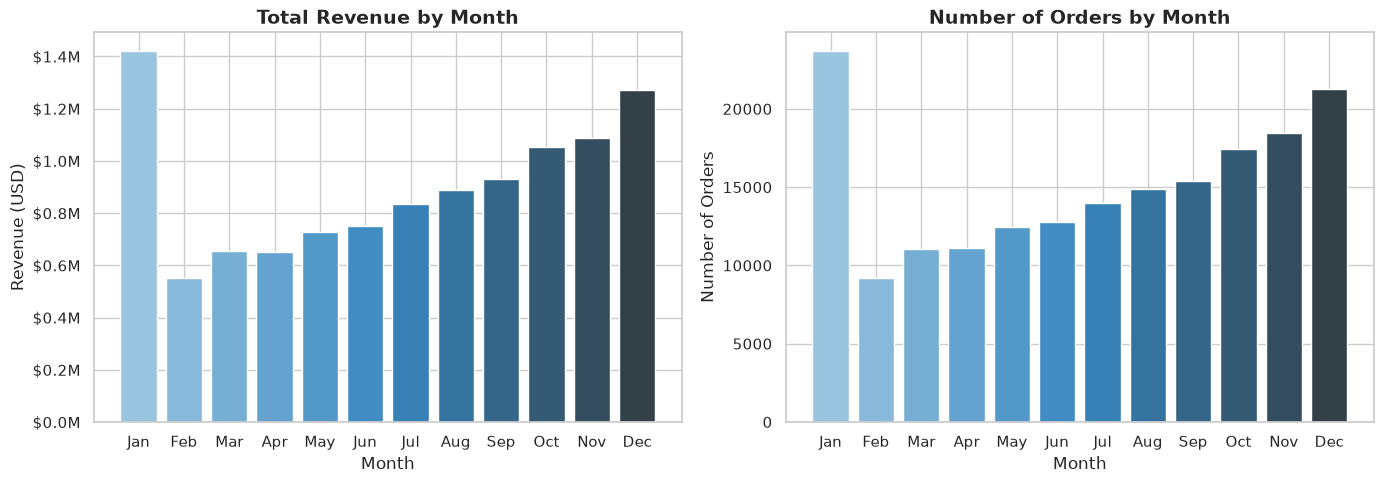

month_name  total_revenue  total_orders
       Jan     1421948.96         23719
       Feb      550918.60          9217
       Mar      653784.88         11072
       Apr      652314.65         11125
       May      727864.92         12436
       Jun      751573.09         12760
       Jul      836410.42         13996
       Aug      886611.10         14880
       Sep      931270.86         15422
       Oct     1053841.67         17435
       Nov     1089063.16         18428
       Dec     1271516.59         21269


In [ ]:
# --- 1.1 Monthly Revenue (aggregated across all years) ---
monthly = df.groupby('month').agg(
    total_revenue=('sale_price', 'sum'),
    total_orders=('order_item_id', 'count')
).reset_index()

month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
monthly['month_name'] = monthly['month'].apply(lambda x: month_names[x-1])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Revenue
bars1 = ax1.bar(monthly['month_name'], monthly['total_revenue'], color=sns.color_palette('Blues_d', 12))
ax1.set_title('Total Revenue by Month', fontsize=14, fontweight='bold')
ax1.set_xlabel('Month')
ax1.set_ylabel('Revenue (USD)')
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))

# Orders
bars2 = ax2.bar(monthly['month_name'], monthly['total_orders'], color=sns.color_palette('Blues_d', 12))
ax2.set_title('Number of Orders by Month', fontsize=14, fontweight='bold')
ax2.set_xlabel('Month')
ax2.set_ylabel('Number of Orders')

plt.tight_layout()
plt.savefig('seasonal_monthly.png', dpi=150, bbox_inches='tight')
plt.show()
print(monthly[['month_name','total_revenue','total_orders']].to_string(index=False))

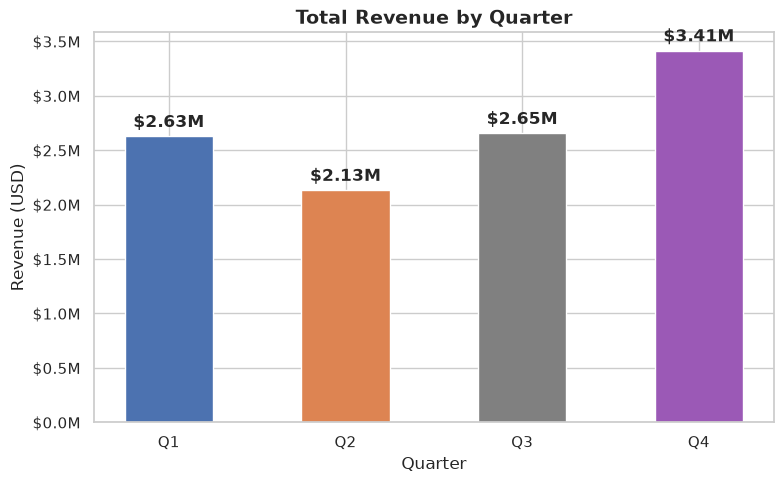

In [ ]:
# --- 1.2 Revenue per Quarter ---
quarterly = df.groupby('quarter').agg(
    total_revenue=('sale_price', 'sum'),
    total_orders=('order_item_id', 'count')
).reset_index()
quarterly['quarter_name'] = quarterly['quarter'].apply(lambda x: f'Q{x}')

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(quarterly['quarter_name'], quarterly['total_revenue'],
             color=['#4C72B0','#DD8452','#808080','#9B59B6'], width=0.5)
ax.set_title('Total Revenue by Quarter', fontsize=14, fontweight='bold')
ax.set_xlabel('Quarter')
ax.set_ylabel('Revenue (USD)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))

# Values above the bars
for bar, val in zip(bars, quarterly['total_revenue']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50000,
            f'${val/1e6:.2f}M', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig('seasonal_quarterly.png', dpi=150, bbox_inches='tight')
plt.show()

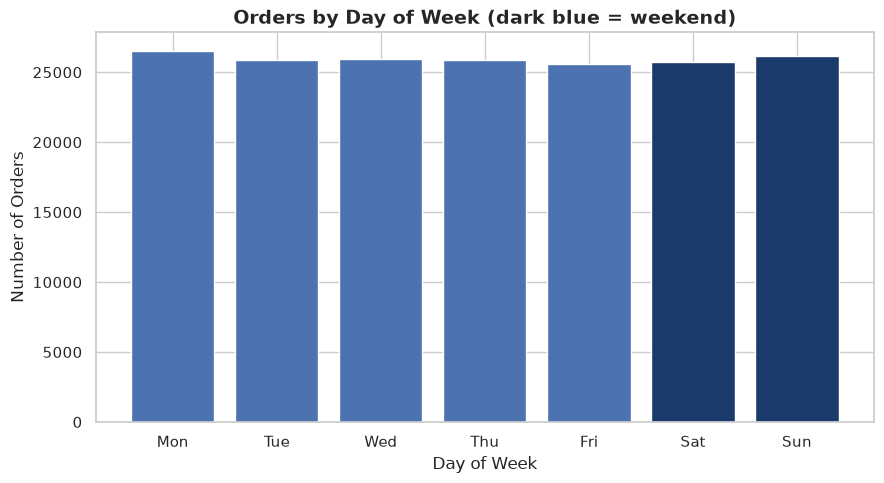

day_name  total_orders  total_revenue
     Mon         26541     1597353.92
     Tue         25902     1537774.77
     Wed         25947     1554187.38
     Thu         25891     1539191.36
     Fri         25562     1521524.84
     Sat         25758     1513164.49
     Sun         26158     1563922.14


In [ ]:
# --- 1.3 Weekday Analysis ---
day_names = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
daily = df.groupby('day_of_week').agg(
    total_revenue=('sale_price', 'sum'),
    total_orders=('order_item_id', 'count')
).reset_index()
daily['day_name'] = daily['day_of_week'].apply(lambda x: day_names[x-1] if x <= 7 else str(x))

fig, ax = plt.subplots(figsize=(9, 5))
colors = ['#1A3A6B' if i >= 5 else '#4C72B0' for i in range(len(daily))]
ax.bar(daily['day_name'], daily['total_orders'], color=colors)
ax.set_title('Orders by Day of Week (dark blue = weekend)', fontsize=14, fontweight='bold')
ax.set_xlabel('Day of Week')
ax.set_ylabel('Number of Orders')
plt.tight_layout()
plt.savefig('seasonal_weekday.png', dpi=150, bbox_inches='tight')
plt.show()
print(daily[['day_name', 'total_orders', 'total_revenue']].to_string(index=False))

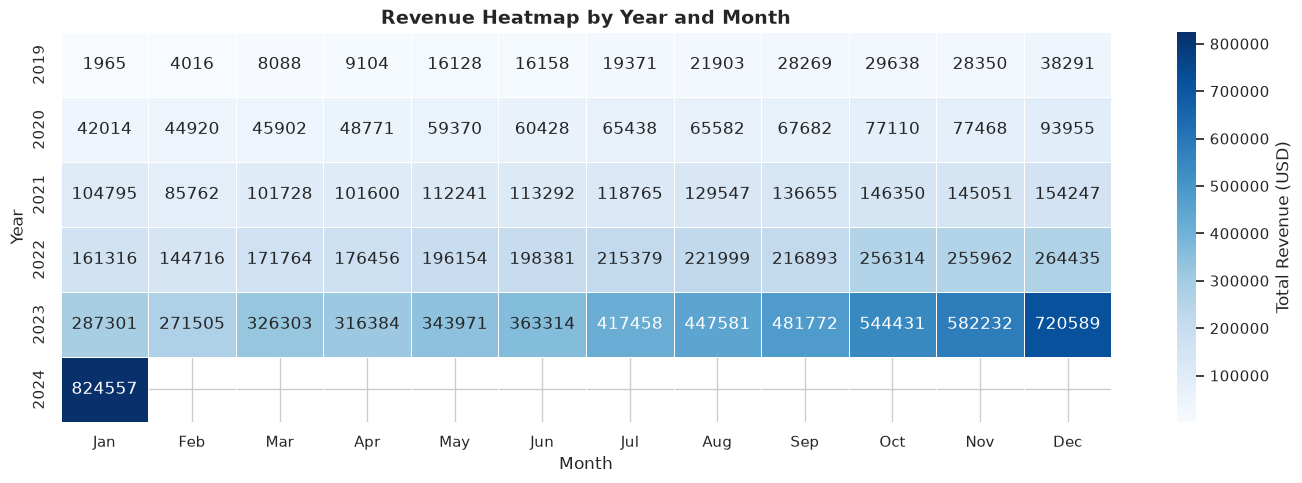

In [ ]:
# --- 2.3 Revenue over time (by year and month) as a heat map ---
pivot = df.groupby(['year','month'])['sale_price'].sum().unstack()
pivot.columns = month_names

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='Blues',
            linewidths=0.5, ax=ax,
            cbar_kws={'label': 'Total Revenue (USD)'})
ax.set_title('Revenue Heatmap by Year and Month', fontsize=14, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Year')
plt.tight_layout()
plt.savefig('seasonal_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

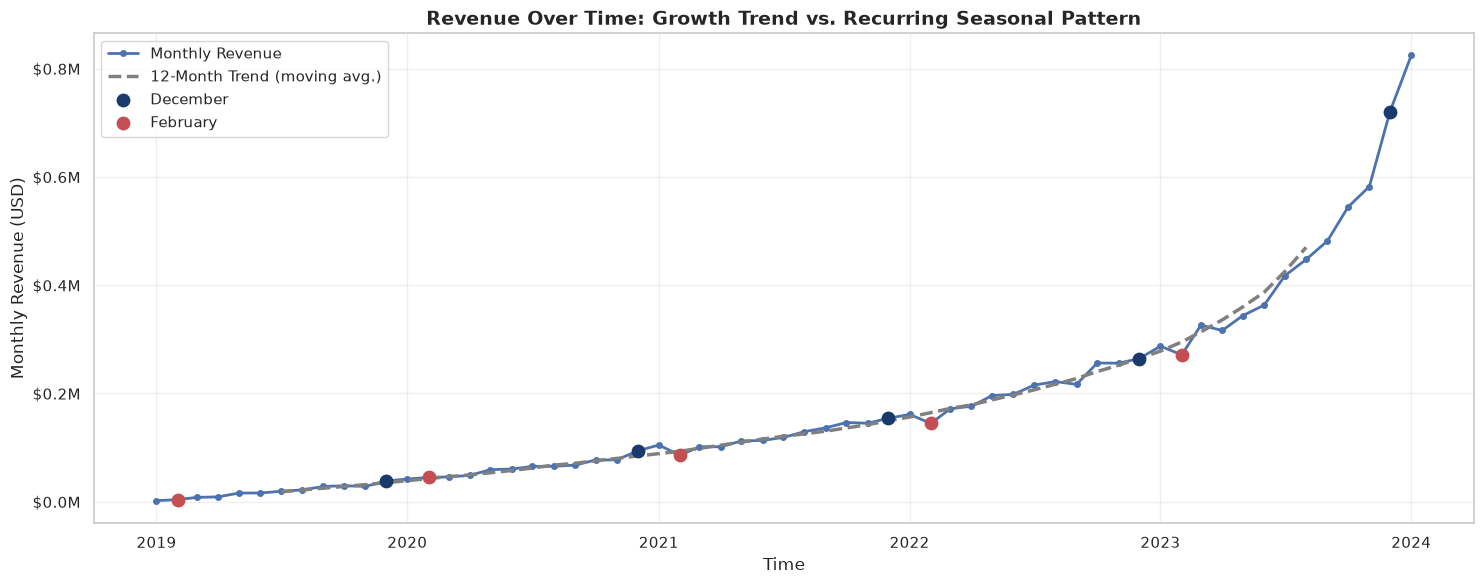

In [ ]:
# --- Time Series: Trend + Seasonality in One Chart ---
ts = df.groupby(['year','month'])['sale_price'].sum().reset_index()
ts['date'] = pd.to_datetime(ts[['year','month']].assign(day=1))
ts = ts.sort_values('date')

# 12-Month Moving Average = Trend
ts['trend'] = ts['sale_price'].rolling(window=12, center=True).mean()

fig, ax = plt.subplots(figsize=(15, 6))

# Actual Values
ax.plot(ts['date'], ts['sale_price'], color='#4C72B0', linewidth=2, marker='o', markersize=4, label='Monthly Revenue')

# Trendline
ax.plot(ts['date'], ts['trend'], color='#808080', linewidth=2.5, linestyle='--', label='12-Month Trend (moving avg.)')

# Mark the December points
dec_points = ts[ts['month'] == 12]
ax.scatter(dec_points['date'], dec_points['sale_price'], color='#1A3A6B', s=80, zorder=5, label='December')

# Mark the February points
feb_points = ts[ts['month'] == 2]
ax.scatter(feb_points['date'], feb_points['sale_price'], color='#C44E52', s=80, zorder=5, label='February')

ax.set_title('Revenue Over Time: Growth Trend vs. Recurring Seasonal Pattern', fontsize=14, fontweight='bold')
ax.set_xlabel('Time')
ax.set_ylabel('Monthly Revenue (USD)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('seasonal_timeseries.png', dpi=150, bbox_inches='tight')
plt.show()

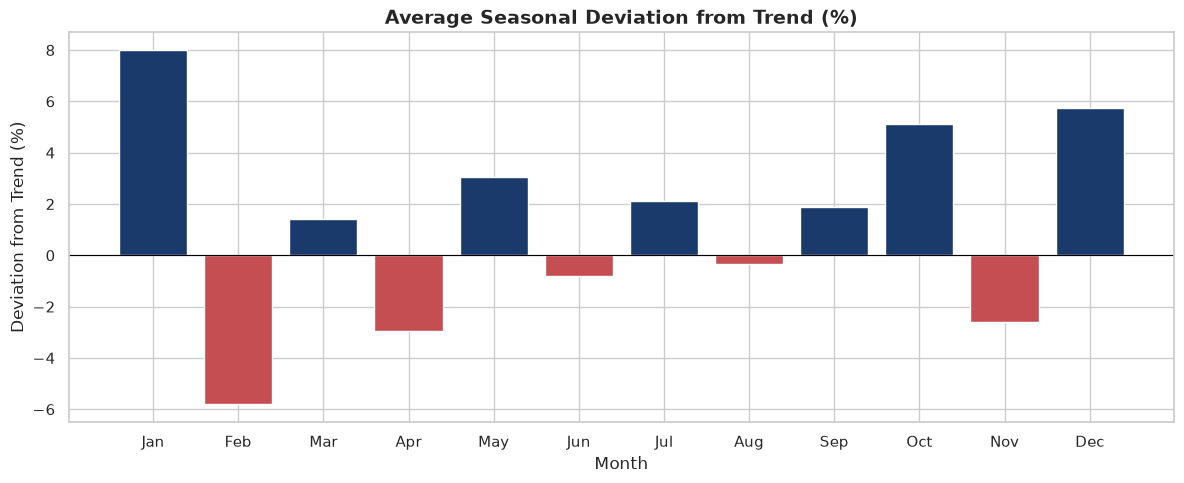

month_name  deviation_pct
       Jan       8.008448
       Feb      -5.805932
       Mar       1.396037
       Apr      -2.964332
       May       3.068830
       Jun      -0.811262
       Jul       2.123812
       Aug      -0.357415
       Sep       1.884112
       Oct       5.099495
       Nov      -2.606345
       Dec       5.739109


In [ ]:
# Deviation from the trend, in percent
ts = df.groupby(['year','month'])['sale_price'].sum().reset_index()
ts['date'] = pd.to_datetime(ts[['year','month']].assign(day=1))
ts = ts.sort_values('date').reset_index(drop=True)
ts['trend'] = ts['sale_price'].rolling(window=12, center=True).mean()
ts['deviation_pct'] = (ts['sale_price'] - ts['trend']) / ts['trend'] * 100

# Average deviation per month over all years
month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
seasonal_dev = ts.dropna().groupby('month')['deviation_pct'].mean().reset_index()
seasonal_dev['month_name'] = seasonal_dev['month'].apply(lambda x: month_names[x-1])

fig, ax = plt.subplots(figsize=(12, 5))
colors = ['#1A3A6B' if v > 0 else '#C44E52' for v in seasonal_dev['deviation_pct']]
ax.bar(seasonal_dev['month_name'], seasonal_dev['deviation_pct'], color=colors)
ax.axhline(y=0, color='black', linewidth=0.8)
ax.set_title('Average Seasonal Deviation from Trend (%)', fontsize=14, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Deviation from Trend (%)')
plt.tight_layout()
plt.savefig('seasonal_deviation.png', dpi=150, bbox_inches='tight')
plt.show()
print(seasonal_dev[['month_name','deviation_pct']].to_string(index=False))

## Part 2: Impact of U.S. Holidays

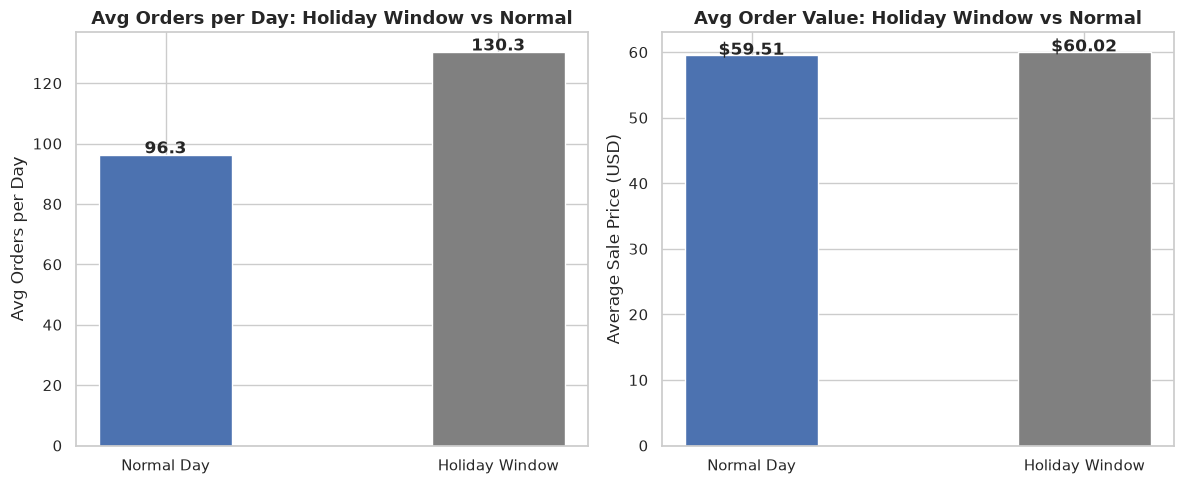

            label  num_days  total_orders  avg_orders_per_day  avg_order_value
0      Normal Day      1659        159734           96.283303        59.506285
1  Holiday Window       169         22025          130.325444        60.020064


In [ ]:
# Number of unique days per group
dim_date_raw = pd.read_csv('/home/jovyan/work/Admin/Download_Data/Datamart_Tables/CSV/datamart_dim_date.csv')
dim_date_raw['date_key'] = pd.to_datetime(dim_date_raw['date_key'])

# Find all holidays
holiday_dates = set(dim_date_raw[dim_date_raw['is_public_holiday'] == True]['date_key'])

# Add 1 day before and after
extended_holidays = set()
for d in holiday_dates:
    extended_holidays.add(d - pd.Timedelta(days=1))
    extended_holidays.add(d)
    extended_holidays.add(d + pd.Timedelta(days=1))

# New Column in df
df['date_key_dt'] = pd.to_datetime(df['date_key'])
df['is_holiday_window'] = df['date_key_dt'].isin(extended_holidays)

# Comparison with Holiday Window
days_count = df.groupby('is_holiday_window')['date_key'].nunique().reset_index()
days_count.columns = ['is_holiday_window', 'num_days']

holiday_compare = df.groupby('is_holiday_window').agg(
    total_orders=('order_item_id', 'count'),
    avg_order_value=('sale_price', 'mean')
).reset_index().merge(days_count, on='is_holiday_window')

holiday_compare['avg_orders_per_day'] = holiday_compare['total_orders'] / holiday_compare['num_days']
holiday_compare['label'] = holiday_compare['is_holiday_window'].map({False: 'Normal Day', True: 'Holiday Window'})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1 - Avg Orders per Day
bars1 = ax1.bar(holiday_compare['label'], holiday_compare['avg_orders_per_day'],
                color=['#4C72B0','#808080'], width=0.4)
ax1.set_title('Avg Orders per Day: Holiday Window vs Normal', fontsize=13, fontweight='bold')
ax1.set_ylabel('Avg Orders per Day')
for bar, val in zip(bars1, holiday_compare['avg_orders_per_day']):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{val:.1f}', ha='center', fontweight='bold')

# Plot 2 - Avg Order Value
bars2 = ax2.bar(holiday_compare['label'], holiday_compare['avg_order_value'],
                color=['#4C72B0','#808080'], width=0.4)
ax2.set_title('Avg Order Value: Holiday Window vs Normal', fontsize=13, fontweight='bold')
ax2.set_ylabel('Average Sale Price (USD)')
for bar, val in zip(bars2, holiday_compare['avg_order_value']):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
             f'${val:.2f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('holiday_window_vs_normal.png', dpi=150, bbox_inches='tight')
plt.show()
print(holiday_compare[['label','num_days','total_orders','avg_orders_per_day','avg_order_value']])

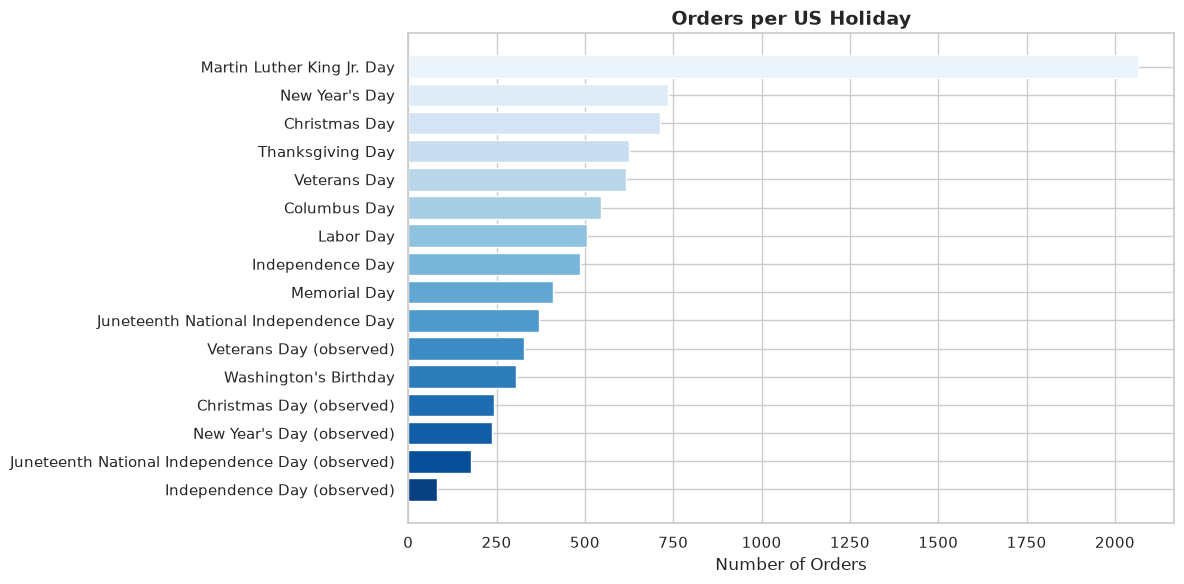

                                   holiday_name  total_orders  total_revenue  avg_order_value
                     Martin Luther King Jr. Day          2064      133723.08        64.788314
                                 New Year's Day           735       46554.88        63.339973
                                  Christmas Day           713       43325.98        60.765750
                               Thanksgiving Day           625       37683.90        60.294240
                                   Veterans Day           615       36038.38        58.598992
                                   Columbus Day           547       34889.13        63.782687
                                      Labor Day           506       30981.55        61.228360
                               Independence Day           486       28785.26        59.228930
                                   Memorial Day           409       24739.07        60.486724
           Juneteenth National Independence Day           37

In [ ]:
# --- 2.2 Which holiday has the greatest impact? ---
holiday_detail = df[df['is_public_holiday'] == True].groupby('holiday_name').agg(
    total_orders=('order_item_id', 'count'),
    total_revenue=('sale_price', 'sum'),
    avg_order_value=('sale_price', 'mean')
).reset_index().sort_values('total_orders', ascending=False)

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(holiday_detail['holiday_name'], holiday_detail['total_orders'],
               color=sns.color_palette('Blues', len(holiday_detail)))
ax.set_title('Orders per US Holiday', fontsize=14, fontweight='bold')
ax.set_xlabel('Number of Orders')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('holiday_detail.png', dpi=150, bbox_inches='tight')
plt.show()
print(holiday_detail.to_string(index=False))